# 特徵工程與轉化傾向模型

**目的**：替分析母體（7,717 位未理財客戶）估計「3 個月內開始定期定額」的機率，用來排序「該優先接觸誰」。

| 步驟 | 內容 |
| --- | --- |
| 1 | 依業務假設建立特徵（只用 2026/08 以前的資料） |
| 2 | 檢查 EDA 沒驗證過的特徵：分組轉化率 |
| 3 | 檢查特徵之間的共線性（VIF） |
| 4 | 分層抽樣切分訓練集／測試集，訓練邏輯迴歸 |
| 5 | 評估：AUC、PR-AUC、Lift / Gains、校準 |
| 6 | 係數表：哪些特徵影響轉化、影響多大 |
| 7 | 確認兩個特徵設計的決定：年資、收入 |
| 8 | 對答案：和理論 AUC 上限比較 |
| 9 | 替全部分析母體評分，輸出給期望價值排序使用 |

> 本專案使用模擬資料，以下所有結果都是**模擬資料中的規律**，在真實情境下是否成立需要驗證（見計畫書 1.5）。

## 0. 環境設定與讀取資料

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.api as sm
import os, subprocess
import matplotlib.font_manager as fm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# Colab沒有內建中文字型,找不到時自動安裝 Noto Sans CJK
CJK_FONT = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
if not any(f.name.startswith(("Microsoft JhengHei", "PingFang", "Heiti", "Noto Sans CJK")) for f in fm.fontManager.ttflist):
    if not os.path.exists(CJK_FONT):
        subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"], check=True)
    fm.fontManager.addfont(CJK_FONT)

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "PingFang TC", "Heiti TC", "Noto Sans CJK TC", "Noto Sans CJK JP", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

MAIN = "#2a78d6"     # 模型
REF = "#52514e"      # 參考線(整體轉化率、隨機)
MUTED = "#a8a7a2"    # 次要資訊

pd.set_option("display.max_columns", None)
DATA = "data_cleaned/"
SEED = 42

In [2]:
def path(name, folder):
    """Colab 直接上傳時檔案在根目錄;下載整個 repo 執行時在資料夾裡"""
    return name if os.path.exists(name) else os.path.join(folder, name)

client_profile = pd.read_csv(path("client_profile_cleaned.csv", "data_cleaned"))
deposit_balance = pd.read_csv(path("deposit_balance_cleaned.csv", "data_cleaned"), parse_dates=["month"])
card_transactions = pd.read_csv(path("card_transactions_cleaned.csv", "data_cleaned"), parse_dates=["transaction_month"])
conversion_label = pd.read_csv(path("conversion_label_cleaned.csv", "data_cleaned"))

# 時間檢查:特徵只能用切點(2026/08)以前的資料
print("活存期間:", deposit_balance["month"].min().date(), "~", deposit_balance["month"].max().date())
print("刷卡期間:", card_transactions["transaction_month"].min().date(), "~", card_transactions["transaction_month"].max().date())
assert deposit_balance["month"].max() <= pd.Timestamp("2026-08-01")
assert card_transactions["transaction_month"].max() <= pd.Timestamp("2026-08-01")

活存期間: 2025-08-01 ~ 2026-07-01
刷卡期間: 2026-03-01 ~ 2026-08-01


## 1. 建立特徵

每個特徵都對應一個業務假設（計畫書 4.2）。年收入不放入模型（EDA Q4：控制餘額後沒有獨立影響），第 7 節再用模型確認。

| 業務假設 | 特徵 | 定義 | EDA 驗證 |
| --- | --- | --- | --- |
| 手上有閒錢的人比較會投資 | `log_balance` | 2025/08–2026/07 平均活存餘額，取 log10（EDA Q1：右偏） | ✅ Q2 |
| 存款越來越多的人有投資需求 | `balance_growth` | 12 個月活存餘額的**每月成長率**：線性迴歸斜率 ÷ 平均餘額 | ❌ |
| 往來越久，越信任銀行 | `tenure_5y` | 往來年資 ≥ 5 年 = 1（原本設計為連續的年資，第 2 節發現台階式關係後改為旗標，見第 7 節） | ❌ |
| 對理財有興趣的人比較會轉化 | `has_app_click` | 近 6 個月有 App 理財點擊 = 1 | ✅ Q5 |
| 風險承受度影響投資意願 | `kyc_穩健型`、`kyc_積極型` | 虛擬變數，保守型為基準 | ✅ Q6 |
| 人生階段影響理財需求 | `age`、`has_children` | 主檔欄位 | ❌ |
| 消費穩定的人比較能固定扣款 | `spend_cv` | 2026/03–2026/08 每月刷卡總額的變異係數（標準差 ÷ 平均），越小越穩定 | ❌ |

**為什麼用「成長率」而不是「斜率」？** 斜率的單位是「每月增加幾元」，餘額 100 萬的客戶每月多 1,000 元和餘額 1 萬的客戶每月多 1,000 元，意義完全不同。除以平均餘額之後，代表「每月成長幾 %」，不同餘額的客戶可以比較，極端值也少很多（見下方輸出：超過 3 個標準差的客戶從 170 人降到 70 人，最大值從 18.6 降到 5.6 個標準差）。

In [3]:
# 活存:平均餘額與每月成長率(12 個月)
bal_wide = deposit_balance.pivot(index="customer_id", columns="month", values="checking_balance").sort_index(axis=1)
assert bal_wide.notna().all().all() and bal_wide.shape[1] == 12
t = np.arange(12) - 5.5                                   # 月份置中
slope = (bal_wide.values - bal_wide.values.mean(axis=1, keepdims=True)) @ t / (t @ t)
balance_feat = pd.DataFrame({
    "avg_balance_12m": bal_wide.mean(axis=1),
    "balance_slope": slope,                               # 每月增加幾元(只用來比較,不進模型)
}, index=bal_wide.index)
balance_feat["balance_growth"] = balance_feat["balance_slope"] / balance_feat["avg_balance_12m"]

# 刷卡:每月刷卡總額的變異係數(6 個月)
spend_wide = card_transactions.pivot_table(index="customer_id", columns="transaction_month",
                                           values="transaction_amount", aggfunc="sum", fill_value=0)
assert spend_wide.shape[1] == 6
spend_feat = pd.DataFrame({"spend_cv": spend_wide.std(axis=1, ddof=0) / spend_wide.mean(axis=1)})

# 極端值比較:斜率 vs 成長率(標準化後超過 3 個標準差的人數)
for col in ["balance_slope", "balance_growth"]:
    z = (balance_feat[col] - balance_feat[col].mean()) / balance_feat[col].std()
    print(f"{col:15s} |z|>3 的客戶: {(z.abs() > 3).sum():4d} 人,最大 |z| = {z.abs().max():.1f}")
print("斜率與平均餘額的相關係數:", round(balance_feat[["balance_slope", "avg_balance_12m"]].corr(method="spearman").iloc[0, 1], 2),
      "| 成長率與平均餘額:", round(balance_feat[["balance_growth", "avg_balance_12m"]].corr(method="spearman").iloc[0, 1], 2))

balance_slope   |z|>3 的客戶:  170 人,最大 |z| = 18.6
balance_growth  |z|>3 的客戶:   70 人,最大 |z| = 5.6
斜率與平均餘額的相關係數: 0.12 | 成長率與平均餘額: 0.14


In [4]:
df = (client_profile
      .merge(conversion_label[["customer_id", "converted_to_sip"]], on="customer_id", how="left")
      .merge(balance_feat, left_on="customer_id", right_index=True, how="left")
      .merge(spend_feat, left_on="customer_id", right_index=True, how="left"))

df["log_balance"] = np.log10(df["avg_balance_12m"])
df["tenure_years"] = df["tenure_months"] / 12           # 只用於第 2 節分組與第 7 節比較
df["tenure_5y"] = (df["tenure_months"] >= 60).astype(int)
df["has_app_click"] = (df["app_click_count_6m"] > 0).astype(int)
df["has_children"] = df["has_children"].astype(int)
df["kyc_穩健型"] = (df["kyc_risk_rating"] == "穩健型").astype(int)
df["kyc_積極型"] = (df["kyc_risk_rating"] == "積極型").astype(int)
df["y"] = df["converted_to_sip"].astype(int)

FEATURES = ["log_balance", "balance_growth", "tenure_5y", "has_app_click",
            "kyc_穩健型", "kyc_積極型", "age", "has_children", "spend_cv"]

# 分析母體:未持有理財商品
target = df[~df["has_wealth_product"]].copy().reset_index(drop=True)
assert target["customer_id"].is_unique and len(target) == 7717
assert target[FEATURES + ["tenure_years", "y"]].notna().all().all()
print("分析母體:", len(target), "人,轉化率", f"{target['y'].mean():.1%}")
target[FEATURES].describe().T.round(3)

分析母體: 7717 人,轉化率 6.7%


,count,mean,std,min,25%,50%,75%,max
log_balance,7717.0,4.701,0.343,3.418,4.468,4.708,4.934,6.020
balance_growth,7717.0,-0.002,0.022,-0.123,-0.015,-0.000,0.013,0.054
tenure_5y,7717.0,0.255,0.436,0.000,0.000,0.000,1.000,1.000
has_app_click,7717.0,0.301,0.459,0.000,0.000,0.000,1.000,1.000
kyc_穩健型,7717.0,0.366,0.482,0.000,0.000,0.000,1.000,1.000
kyc_積極型,7717.0,0.261,0.439,0.000,0.000,0.000,1.000,1.000
age,7717.0,37.731,10.420,20.000,30.000,37.000,45.000,70.000
has_children,7717.0,0.489,0.500,0.000,0.000,0.000,1.000,1.000
spend_cv,7717.0,0.111,0.043,0.013,0.080,0.105,0.135,0.368


## 2. EDA 沒驗證過的特徵：分組轉化率

成長率、年資、年齡、有無子女、刷卡波動在 EDA 中沒有看過。放進模型之前，先用和 EDA 相同的方法（分組轉化率 + 95% 信賴區間）看一次，對後面的係數表有個預期。

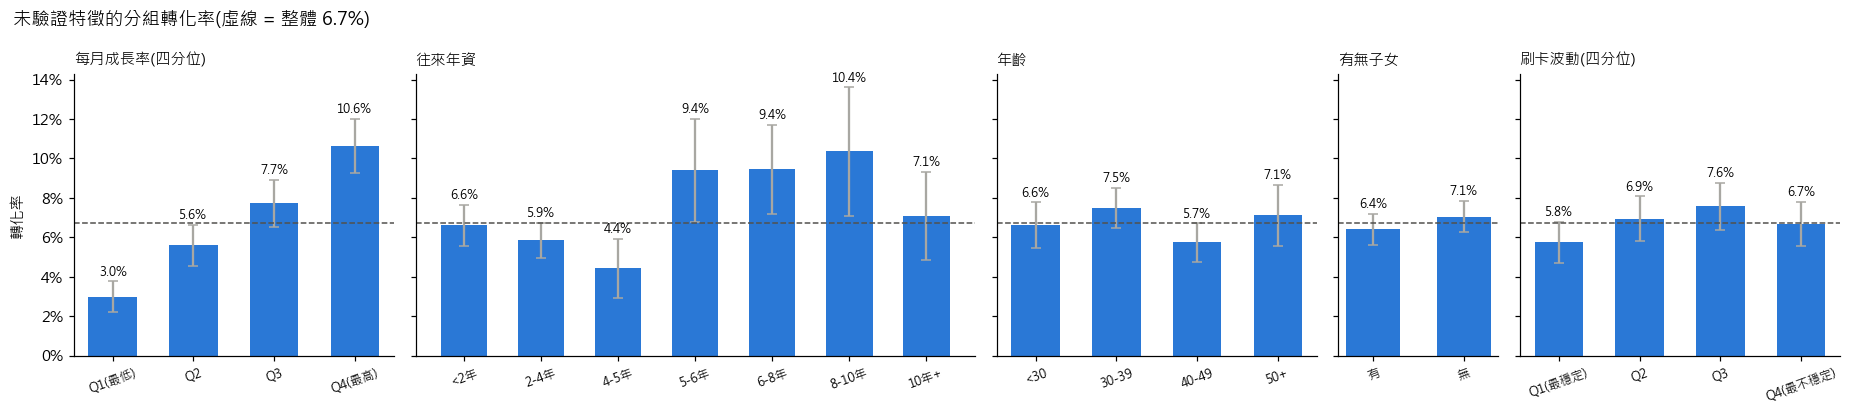

In [5]:
base_rate = target["y"].mean()

def conv_table(data, by):
    t = data.groupby(by, observed=True)["y"].agg(人數="size", 轉化人數="sum")
    t["轉化率"] = t["轉化人數"] / t["人數"]
    t["誤差"] = 1.96 * np.sqrt(t["轉化率"] * (1 - t["轉化率"]) / t["人數"])
    return t

checks = {
    "balance_growth": ("每月成長率(四分位)", pd.qcut(target["balance_growth"], 4, labels=["Q1(最低)", "Q2", "Q3", "Q4(最高)"])),
    "tenure_years": ("往來年資", pd.cut(target["tenure_years"], [0, 2, 4, 5, 6, 8, 10, np.inf], right=False,
                                         labels=["<2年", "2-4年", "4-5年", "5-6年", "6-8年", "8-10年", "10年+"])),
    "age": ("年齡", pd.cut(target["age"], [0, 30, 40, 50, np.inf], right=False, labels=["<30", "30-39", "40-49", "50+"])),
    "has_children": ("有無子女", target["has_children"].map({0: "無", 1: "有"})),
    "spend_cv": ("刷卡波動(四分位)", pd.qcut(target["spend_cv"], 4, labels=["Q1(最穩定)", "Q2", "Q3", "Q4(最不穩定)"])),
}

fig, axes = plt.subplots(1, 5, figsize=(17, 3.8), sharey=True, gridspec_kw={"width_ratios": [4, 7, 4, 2, 4]})
tables = {}
for ax, (col, (title, groups)) in zip(axes, checks.items()):
    t = conv_table(target, groups)
    tables[col] = t
    x = np.arange(len(t))
    ax.bar(x, t["轉化率"], yerr=t["誤差"], color=MAIN, width=0.6, ecolor=MUTED, capsize=3)
    ax.axhline(base_rate, color=REF, linestyle="--", linewidth=1)
    for i, r in enumerate(t["轉化率"]):
        ax.text(i, r + t["誤差"].iloc[i] + 0.003, f"{r:.1%}", ha="center", fontsize=8)
    ax.set_xticks(x, t.index.astype(str), rotation=20, fontsize=8)
    ax.set_title(title, loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[0].set_ylabel("轉化率")
fig.suptitle(f"未驗證特徵的分組轉化率(虛線 = 整體 {base_rate:.1%})", x=0.01, ha="left")
plt.tight_layout()
plt.show()

pd.concat({k: v[["人數", "轉化率"]] for k, v in tables.items()}).style.format({"轉化率": "{:.1%}"})

**我的解讀**：

在模擬資料中，

成長率：Q1 到 Q4 是 3.0% → 10.6%，一路上升

年資：4–5 年 4.4% → 5–6 年 9.4%，台階形狀

年齡、有無子女、刷卡波動：沒有一致的上升或下降，各組信賴區間大多重疊


**年資的設計調整**：年資的轉化率不是隨年資逐年上升，而是在 **5 年**前後跳一階（4–5 年 vs 5–6 年），之後大致持平，像「台階」而不是「斜坡」。邏輯迴歸假設連續特徵的影響是直線的，用連續年資會把台階攤平，低估年資的影響。因此改用「年資 ≥ 5 年」的旗標：

- **業務理由**：5 年是常見的整數門檻，不是從資料中挑出最好看的切點。
- **資料理由**：跳升明顯，不是勉強挑出的差距。
- **限制**：門檻是看過資料後決定的；10 年以上的轉化率回落，但人數少、信賴區間寬，旗標把 5 年以上視為同一群。兩種設計的比較見第 7 節。

## 3. 共線性檢查

邏輯迴歸的係數是「**其他特徵不變時**」的影響。如果某個特徵可以被其他特徵解釋，模型很難分開它們各自的效果，係數會不穩定、甚至方向相反。

**VIF（變異數膨脹因子）**：用其他**所有**特徵去預測這個特徵，看它被解釋了多少。VIF = k 代表這個特徵係數的變異被放大 k 倍。一般 > 5 需要注意，> 10 代表嚴重共線性。

In [6]:
X_vif = sm.add_constant(target[FEATURES].astype(float))
vif = pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])], index=FEATURES, name="VIF")
vif.round(2).to_frame()

,VIF
log_balance,1.02
balance_growth,1.02
tenure_5y,1.00
has_app_click,1.00
kyc_穩健型,1.26
kyc_積極型,1.28
age,1.02
has_children,1.00
spend_cv,1.00


**我的解讀**：

在模擬資料中，最高的是 KYC_積極型 的 1.28，全部都遠低於 5

第 6 節的係數可以分開解讀。

## 4. 切分資料與訓練模型

- **分層抽樣**：轉化率只有 6.7%，用 `stratify=y` 確保訓練集和測試集的轉化率相同。
- **標準化**：特徵單位不同（年、%、log 元），標準化後係數代表「特徵增加 1 個標準差」的影響，可以互相比較大小。
- **不設定 `class_weight="balanced"`**：這個設定會把預測機率整體拉高，排序不受影響，但第 4.4 節的期望價值 = 機率 × 手續費需要**接近真實的機率**。類別不平衡改用分層抽樣和 PR-AUC 處理。

In [7]:
X, y = target[FEATURES], target["y"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
print(f"訓練集: {len(X_train):,} 人,轉化 {y_train.sum()} 人({y_train.mean():.2%})")
print(f"測試集: {len(X_test):,} 人,轉化 {y_test.sum()} 人({y_test.mean():.2%})")

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
p_test = model.predict_proba(X_test)[:, 1]

訓練集: 5,401 人,轉化 364 人(6.74%)
測試集: 2,316 人,轉化 156 人(6.74%)


## 5. 模型評估（測試集）

| 指標 | 回答的問題 | 比較基準 |
| --- | --- | --- |
| AUC-ROC | 隨機挑一位轉化、一位未轉化的客戶，模型把轉化者排在前面的機率 | 隨機 = 0.5；理論上限見第 8 節 |
| PR-AUC | 名單中真正會轉化的比例（精確率）平均有多高；類別不平衡時比 AUC 更嚴格 | 隨機 = 整體轉化率 6.7% |
| Lift | 依模型挑前 X% 客戶，轉化率是隨機挑的幾倍 | 隨機 = 1 |
| 校準 | 預測機率的大小是否接近實際轉化率（期望價值排序會直接使用機率） | Lift 表中「平均預測機率」與「實際轉化率」兩欄越接近越好 |

In [8]:
auc = roc_auc_score(y_test, p_test)
pr_auc = average_precision_score(y_test, p_test)
print(f"AUC-ROC: {auc:.3f}")
print(f"PR-AUC : {pr_auc:.3f}(隨機基準 {y_test.mean():.3f},約 {pr_auc / y_test.mean():.1f} 倍)")

AUC-ROC: 0.734
PR-AUC : 0.221(隨機基準 0.067,約 3.3 倍)


In [9]:
# 依預測機率分 10 組(第 1 組 = 機率最高的 10%)
eval_df = pd.DataFrame({"y": y_test.values, "p": p_test})
eval_df["組別"] = pd.qcut(eval_df["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = eval_df.groupby("組別", observed=True).agg(人數=("y", "size"), 轉化人數=("y", "sum"), 平均預測機率=("p", "mean"))
lift["實際轉化率"] = lift["轉化人數"] / lift["人數"]
lift["Lift"] = lift["實際轉化率"] / y_test.mean()
lift["累積抓到的轉化者"] = lift["轉化人數"].cumsum() / lift["轉化人數"].sum()
lift.index = [f"前{i * 10}%" if i == 1 else f"{(i - 1) * 10}-{i * 10}%" for i in lift.index]
lift.style.format({"平均預測機率": "{:.1%}", "實際轉化率": "{:.1%}", "Lift": "{:.2f}", "累積抓到的轉化者": "{:.0%}"})

,人數,轉化人數,平均預測機率,實際轉化率,Lift,累積抓到的轉化者
前10%,232,51,19.8%,22.0%,3.26,33%
10-20%,232,30,11.5%,12.9%,1.92,52%
20-30%,231,17,8.6%,7.4%,1.09,63%
30-40%,232,15,6.8%,6.5%,0.96,72%
40-50%,231,10,5.6%,4.3%,0.64,79%
50-60%,232,11,4.5%,4.7%,0.70,86%
60-70%,231,5,3.6%,2.2%,0.32,89%
70-80%,232,4,2.8%,1.7%,0.26,92%
80-90%,231,7,2.0%,3.0%,0.45,96%
90-100%,232,6,1.1%,2.6%,0.38,100%


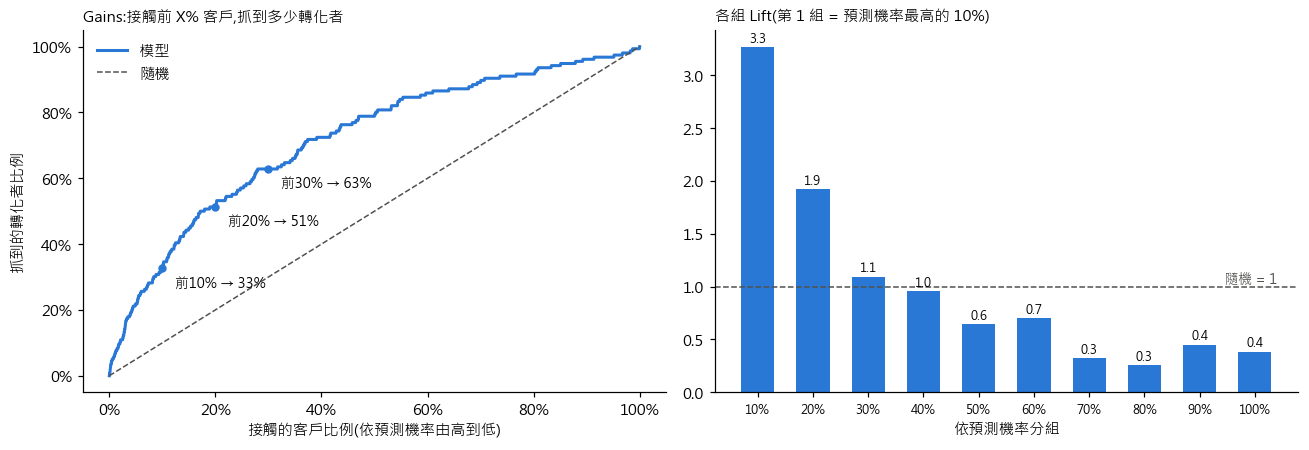

前 20% 名單:轉化率 17.3%,Lift 2.57,抓到 51% 的轉化者
校準:測試集平均預測機率 6.64% vs 實際轉化率 6.74%


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# 左:Gains 曲線(接觸前 X% 客戶,能抓到多少比例的轉化者)
order = np.argsort(-p_test)
gains = np.concatenate([[0], np.cumsum(y_test.values[order]) / y_test.sum()])
share = np.linspace(0, 1, len(gains))
axes[0].plot(share, gains, color=MAIN, linewidth=2, label="模型")
axes[0].plot([0, 1], [0, 1], color=REF, linestyle="--", linewidth=1, label="隨機")
for q in [0.1, 0.2, 0.3]:
    g = gains[int(q * (len(gains) - 1))]
    axes[0].scatter(q, g, color=MAIN, zorder=3, s=20)
    axes[0].annotate(f"前{q:.0%} → {g:.0%}", (q, g), textcoords="offset points", xytext=(8, -12), fontsize=9)
axes[0].set_title("Gains:接觸前 X% 客戶,抓到多少轉化者", loc="left", fontsize=10)
axes[0].set_xlabel("接觸的客戶比例(依預測機率由高到低)")
axes[0].set_ylabel("抓到的轉化者比例")
axes[0].legend(frameon=False)

# 右:各組 Lift
axes[1].bar(range(10), lift["Lift"], color=MAIN, width=0.6)
axes[1].axhline(1, color=REF, linestyle="--", linewidth=1)
axes[1].text(9.4, 1, " 隨機 = 1", va="bottom", ha="right", color=REF, fontsize=9)
for i, v in enumerate(lift["Lift"]):
    axes[1].text(i, v + 0.05, f"{v:.1f}", ha="center", fontsize=8)
axes[1].set_xticks(range(10), [f"{(i + 1) * 10}%" for i in range(10)], fontsize=8)
axes[1].set_title("各組 Lift(第 1 組 = 預測機率最高的 10%)", loc="left", fontsize=10)
axes[1].set_xlabel("依預測機率分組")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
plt.tight_layout()
plt.show()

top20 = eval_df.nlargest(int(len(eval_df) * 0.2), "p")
print(f"前 20% 名單:轉化率 {top20['y'].mean():.1%},Lift {top20['y'].mean() / y_test.mean():.2f},抓到 {top20['y'].sum() / y_test.sum():.0%} 的轉化者")
print(f"校準:測試集平均預測機率 {p_test.mean():.2%} vs 實際轉化率 {y_test.mean():.2%}")

**我的解讀**：

在模擬資料中，AUC: 0.734，隨機挑一位轉化、一位未轉化的客戶，模型把轉化者排在前面的機率是 73.4%，比隨機的0.5高

PR-AUC: 0.221，是隨機挑選客戶轉化率(0.067)的約3.3倍

接觸前20%的客戶的轉化率是 17.3%，抓到 51% 的轉化者。
轉化率為隨機的2.57 倍

平均預測 6.64% vs 實際 6.74%，非常接近，可以直接用來計算期望價值

## 6. 係數表：哪些特徵影響轉化？

- **標準化係數**：特徵增加 1 個標準差，log-odds 增加多少。可以互相比較大小。
- **勝算比**（Odds Ratio）= e^係數：特徵增加 1 個標準差，轉化的勝算變成幾倍。> 1 提高、< 1 降低。
- **p 值與 95% 信賴區間**：sklearn 不提供，改用 statsmodels 在同一份訓練集上計算。
- 虛擬變數（`tenure_5y`、`has_app_click`、`kyc_*`、`has_children`）也經過標準化，解讀時以「方向」和「相對大小」為主；第二張表另外列出它們**未標準化**的勝算比（例如「有 App 點擊 vs 沒有」）。

In [11]:
scaler = StandardScaler().fit(X_train)
X_train_std = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)
logit_std = sm.Logit(y_train, sm.add_constant(X_train_std)).fit(disp=0)

coef = pd.DataFrame({
    "標準化係數": logit_std.params[FEATURES],
    "勝算比(每 1 SD)": np.exp(logit_std.params[FEATURES]),
    "95%CI 下限": np.exp(logit_std.conf_int().loc[FEATURES, 0]),
    "95%CI 上限": np.exp(logit_std.conf_int().loc[FEATURES, 1]),
    "p 值": logit_std.pvalues[FEATURES],
})
coef["顯著(p<0.05)"] = np.where(coef["p 值"] < 0.05, "是", "否")
coef = coef.sort_values("標準化係數", key=abs, ascending=False)
coef.style.format({"標準化係數": "{:+.3f}", "勝算比(每 1 SD)": "{:.2f}", "95%CI 下限": "{:.2f}",
                   "95%CI 上限": "{:.2f}", "p 值": "{:.4f}"})

,標準化係數,勝算比(每 1 SD),95%CI 下限,95%CI 上限,p 值,顯著(p<0.05)
log_balance,+0.585,1.79,1.60,2.01,0.0000,是
balance_growth,+0.448,1.57,1.38,1.78,0.0000,是
has_app_click,+0.224,1.25,1.13,1.39,0.0000,是
tenure_5y,+0.198,1.22,1.10,1.35,0.0001,是
kyc_積極型,+0.194,1.21,1.07,1.37,0.0019,是
has_children,-0.106,0.90,0.81,1.00,0.0578,否
kyc_穩健型,+0.092,1.10,0.96,1.25,0.1606,否
spend_cv,+0.064,1.07,0.96,1.19,0.2349,否
age,+0.044,1.04,0.94,1.17,0.4346,否


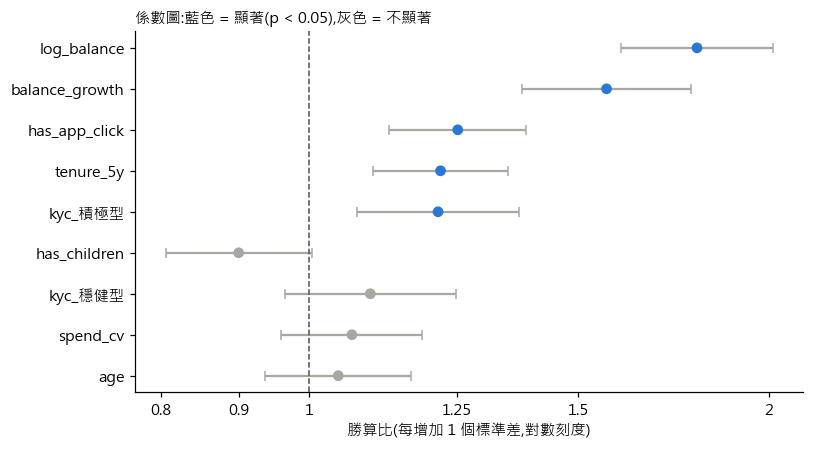

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
c = coef.iloc[::-1]
colors = [MAIN if s == "是" else MUTED for s in c["顯著(p<0.05)"]]
ax.errorbar(c["勝算比(每 1 SD)"], range(len(c)),
            xerr=[c["勝算比(每 1 SD)"] - c["95%CI 下限"], c["95%CI 上限"] - c["勝算比(每 1 SD)"]],
            fmt="none", ecolor=MUTED, capsize=3)
ax.scatter(c["勝算比(每 1 SD)"], range(len(c)), color=colors, zorder=3)
ax.axvline(1, color=REF, linestyle="--", linewidth=1)
ax.set_yticks(range(len(c)), c.index)
ax.set_xscale("log")
ticks = [0.8, 0.9, 1.0, 1.25, 1.5, 2.0]
ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
ax.xaxis.set_minor_locator(mtick.NullLocator())
ax.set_xlabel("勝算比(每增加 1 個標準差,對數刻度)")
ax.set_title("係數圖:藍色 = 顯著(p < 0.05),灰色 = 不顯著", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [13]:
# 虛擬變數未標準化的勝算比:「是 vs 否」的勝算是幾倍,比較直覺
binary = ["tenure_5y", "has_app_click", "kyc_穩健型", "kyc_積極型", "has_children"]
logit_raw = sm.Logit(y_train, sm.add_constant(X_train.astype(float))).fit(disp=0)
pd.DataFrame({
    "比較": ["年資 ≥ 5 年 vs 未滿 5 年", "有 App 點擊 vs 沒有", "穩健型 vs 保守型", "積極型 vs 保守型", "有子女 vs 無子女"],
    "勝算比": np.exp(logit_raw.params[binary]).values,
    "95%CI": [f"{a:.2f} – {b:.2f}" for a, b in np.exp(logit_raw.conf_int().loc[binary]).values],
    "p 值": logit_raw.pvalues[binary].values,
}, index=binary).style.format({"勝算比": "{:.2f}", "p 值": "{:.4f}"})

,比較,勝算比,95%CI,p 值
tenure_5y,年資 ≥ 5 年 vs 未滿 5 年,1.57,1.24 – 1.98,0.0001
has_app_click,有 App 點擊 vs 沒有,1.63,1.30 – 2.04,0.0000
kyc_穩健型,穩健型 vs 保守型,1.21,0.93 – 1.58,0.1606
kyc_積極型,積極型 vs 保守型,1.55,1.18 – 2.05,0.0019
has_children,有子女 vs 無子女,0.81,0.65 – 1.01,0.0578


**我的解讀**：

在模擬資料中，影響最大的三個特徵 : log_balance、balance_growth、has_app_click，五個顯著的特徵係數全部是正的，都和業務假設的方向一致

哪些假設在資料中部份成立、不成立(不顯著):

部分成立:

風險承受度影響投資意願 ：積極型顯著，穩健型不顯著


不成立:

人生階段影響理財需求（年齡 p = 0.43；有無子女 p = 0.058，接近門檻）、

消費穩定的人比較能固定扣款

和第 2 節的分組轉化率一致，成長率都很明顯，年齡、子女、刷卡波動則都沒有規律。

## 7. 確認三個設計決定

用同樣的 5-fold 交叉驗證切分，比較不同設計的 AUC。交叉驗證把資料輪流切成 5 份訓練、驗證，比單次切分更不受運氣影響。**如果兩個版本的 AUC 差距小於交叉驗證的標準差，代表差異可能只是雜訊。**


### 7.1 年資：連續年資 vs 年資 ≥ 5 年旗標

In [14]:
cv_all = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def compare(versions):
    # 同一組 5-fold 切分下,比較各版本的交叉驗證 AUC
    rows = {}
    for name, feats in versions.items():
        s = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                            target[feats], target["y"], cv=cv_all, scoring="roc_auc")
        rows[name] = {"平均 AUC": s.mean(), "標準差": s.std()}
    return pd.DataFrame(rows).T

FEATURES_LINEAR = [f if f != "tenure_5y" else "tenure_years" for f in FEATURES]
display(compare({"連續年資": FEATURES_LINEAR, "年資 ≥ 5 年旗標(採用)": FEATURES})
        .style.format("{:.4f}"))

# 係數:未標準化,訓練集
rows = {}
for name, feats, col, unit in [("連續年資", FEATURES_LINEAR, "tenure_years", "每多 1 年"),
                               ("年資 ≥ 5 年旗標(採用)", FEATURES, "tenure_5y", "滿 5 年 vs 未滿")]:
    m = sm.Logit(y_train, sm.add_constant(target.loc[X_train.index, feats].astype(float))).fit(disp=0)
    rows[name] = {"勝算比的意思": unit, "勝算比": np.exp(m.params[col]), "p 值": m.pvalues[col]}
pd.DataFrame(rows).T.style.format({"勝算比": "{:.3f}", "p 值": "{:.4f}"})

,平均 AUC,標準差
連續年資,0.7123,0.0286
年資 ≥ 5 年旗標(採用),0.7162,0.0276


,勝算比的意思,勝算比,p 值
連續年資,每多 1 年,1.025,0.0992
年資 ≥ 5 年旗標(採用),滿 5 年 vs 未滿,1.570,0.0001


**我的解讀**：

在模擬資料中，此調整改善了解讀:

AUC 幾乎沒變(0.712 vs 0.716，差距小於標準差 0.028。)，

但年資從不顯著變成顯著，反映出 5 年的台階效果。


### 7.2 收入：不放 vs 放入

EDA Q4 判斷收入沒有獨立影響，所以沒有放入模型。這裡用模型再確認一次。

- 收入取 log10；不揭露收入的客戶（`income_was_unknown = 1`）在清洗時已補中位數，這裡再加一個「是否不揭露」的旗標，讓模型自己決定這群人要不要另外調整。

In [15]:
target["log_income"] = np.log10(target["income_annual_wan"])
FEATURES_INC = FEATURES + ["log_income", "income_was_unknown"]
display(compare({"不放收入(採用)": FEATURES, "放入收入": FEATURES_INC}).style.format("{:.4f}"))

logit_inc = sm.Logit(target["y"], sm.add_constant(pd.DataFrame(StandardScaler().fit_transform(target[FEATURES_INC]),
                                                               columns=FEATURES_INC))).fit(disp=0)
print("放入收入後,收入相關係數:")
print(pd.DataFrame({"標準化係數": logit_inc.params[["log_income", "income_was_unknown"]],
                    "p 值": logit_inc.pvalues[["log_income", "income_was_unknown"]]}).round(4))

,平均 AUC,標準差
不放收入(採用),0.7162,0.0276
放入收入,0.7140,0.0249


放入收入後,收入相關係數:
                     標準化係數     p 值
log_income         -0.0299  0.5595
income_was_unknown -0.0020  0.9673


**我的解讀**：

在模擬資料中沒有提升，AUC 0.716 vs 0.714

收入係數 p = 0.56，不顯著。支持 EDA Q4 的結論

### 7.3 類別不平衡：不用 class_weight 或 SMOTE

轉化率只有 6.7%，常見的處理方式是 `class_weight="balanced"`（加重少數類別的權重）或 SMOTE（人工合成少數類別的樣本）。這兩種方法是為了「用 0.5 當門檻做分類」設計的，會把預測機率整體拉高。本專案要的是**排序**和**期望價值 = 機率 × 手續費**，所以需要接近真實的機率。

這裡用第 4 節的同一份測試集比較三種做法（SMOTE 只能在訓練資料上合成樣本，用交叉驗證時每一折都要各自合成，所以改用單次切分比較）。

SMOTE 是依「距離」找最近的鄰居、在兩人之間合成新樣本，所以要**先標準化再合成**（用 imblearn 的 pipeline 把兩步串起來）。如果先合成再標準化，距離幾乎只由數值範圍大的特徵（例如年齡）決定，合成出的樣本會不合理。

In [16]:
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import make_pipeline as imb_pipeline
except ImportError:
    subprocess.run(["pip", "-q", "install", "imbalanced-learn"], check=True)
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import make_pipeline as imb_pipeline

def evaluate(m, X_fit, y_fit):
    p = m.fit(X_fit, y_fit).predict_proba(X_test)[:, 1]
    return {"AUC": roc_auc_score(y_test, p), "平均預測機率": p.mean()}

imbalance = pd.DataFrame({
    "不處理(採用)": evaluate(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), X_train, y_train),
    "class_weight": evaluate(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")), X_train, y_train),
    # SMOTE 依「距離」找鄰居合成樣本,要先標準化,否則距離幾乎只由數值範圍大的特徵(例如年齡)決定
    "SMOTE": evaluate(imb_pipeline(StandardScaler(), SMOTE(random_state=SEED), LogisticRegression(max_iter=1000)), X_train, y_train),
}).T
imbalance["機率放大倍數"] = imbalance["平均預測機率"] / imbalance.loc["不處理(採用)", "平均預測機率"]
print(f"測試集實際轉化率:{y_test.mean():.1%}")
imbalance.style.format({"AUC": "{:.3f}", "平均預測機率": "{:.1%}", "機率放大倍數": "{:.1f} 倍"})

測試集實際轉化率:6.7%


,AUC,平均預測機率,機率放大倍數
不處理(採用),0.734,6.6%,1.0 倍
class_weight,0.733,43.4%,6.5 倍
SMOTE,0.731,42.6%,6.4 倍


**我的解讀**：

不處理的 AUC 是 0.734，平均預測機率 6.6%，接近實際轉化率 6.7%。class_weight:AUC:0.733，平均預測機率:43.4%，機率放大倍數:6.5，
SMOTE:AUC:0.731，平均預測機率:42.6%，機率放大倍數:6.4。

採用的話，class_weight/SMOTE 排序能力不變，但機率放大 6.5/6.4 倍，期望價值會被灌水；

因此不採用這兩種方式，因為期望價值 = 機率 × 手續費，需要接近真實的機率。

## 8. 對答案：和理論 AUC 上限比較

模擬資料的標籤是「依每位客戶的真實機率抽籤」產生的，所以即使知道真實機率，也無法 100% 預測誰會轉化。**直接用真實機率當預測分數算出的 AUC，就是任何模型的上限。**

- 真實機率由 `data_generation/export_true_prob.py` 匯出，只在這一節用來對答案，前面的特徵與模型都沒有使用。
- 用**同一份測試集**計算上限，比較才公平。
- 如果模型 AUC **超過**上限，代表有資料洩漏或評估錯誤。

            AUC     PR-AUC
模型       0.734    0.221
理論上限   0.764    0.246
隨機       0.500    0.067

模型達到理論上限的 89%(以「超過隨機的部分」計算)


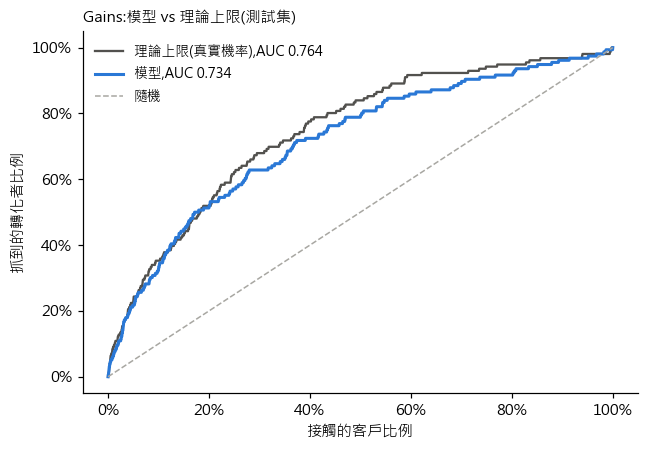

In [17]:
true_prob = pd.read_csv(path("true_prob.csv", "data_cleaned"))
test_ids = target.loc[X_test.index, "customer_id"]
tp = test_ids.to_frame().merge(true_prob, on="customer_id", how="left")["true_prob"].values
assert not np.isnan(tp).any()

ceiling = roc_auc_score(y_test, tp)
ceiling_pr = average_precision_score(y_test, tp)
print(f"            AUC     PR-AUC")
print(f"模型       {auc:.3f}    {pr_auc:.3f}")
print(f"理論上限   {ceiling:.3f}    {ceiling_pr:.3f}")
print(f"隨機       0.500    {y_test.mean():.3f}")
print(f"\n模型達到理論上限的 {(auc - 0.5) / (ceiling - 0.5):.0%}(以「超過隨機的部分」計算)")

# Gains:模型 vs 理論上限
order_tp = np.argsort(-tp)
gains_tp = np.concatenate([[0], np.cumsum(y_test.values[order_tp]) / y_test.sum()])
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(share, gains_tp, color=REF, linewidth=1.5, label=f"理論上限(真實機率),AUC {ceiling:.3f}")
ax.plot(share, gains, color=MAIN, linewidth=2, label=f"模型,AUC {auc:.3f}")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="隨機")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("接觸的客戶比例")
ax.set_ylabel("抓到的轉化者比例")
ax.set_title("Gains:模型 vs 理論上限(測試集)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**我的解讀**：

在模擬資料中，離上限多遠:
0.734 vs 0.764，達到「超過隨機的部分」的 89%。

標籤有隨機性，沒辦法達到1.0。即使用真實機率，AUC 也只有 0.76。

AUC沒有超過理論上限，沒有發現資料洩漏的跡象。

## 9. 替分析母體評分，輸出給期望價值排序

- 用第 4 節訓練好的模型，替全部 7,717 位客戶計算轉化機率。
- **注意**：其中 70% 的客戶是訓練集，他們的分數是「模型看過答案」的分數。**評估模型只能用測試集（第 5 節）**；這份評分只用來產生名單。
- **評估用的分數**：另外用 5-fold 交叉驗證（切法與第 7 節相同）的 `cross_val_predict`，替每位客戶算出「模型沒看過他」的分數 `p_convert_oof`。期望價值排序評估成效時使用，樣本可以擴大到全部客戶，不只測試集。
- `p_convert` 用來**產生名單**；`p_convert_oof` 用來**評估成效**。
- 輸出 `outputs/propensity_scores.csv`，下一階段計算期望價值時使用。

In [18]:
# 評估用:每位客戶的分數來自「沒看過他」的模型(5-fold,切法與第 7 節相同)
target["p_convert_oof"] = cross_val_predict(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    target[FEATURES], target["y"], cv=cv_all, method="predict_proba")[:, 1]
print(f"Out-of-fold AUC: {roc_auc_score(target['y'], target['p_convert_oof']):.3f}")
print(f"平均 OOF 機率 {target['p_convert_oof'].mean():.2%} vs 實際轉化率 {target['y'].mean():.2%}")

Out-of-fold AUC: 0.716
平均 OOF 機率 6.73% vs 實際轉化率 6.74%


In [19]:
target["p_convert"] = model.predict_proba(target[FEATURES])[:, 1]
target["is_test"] = target.index.isin(X_test.index)
target["rank"] = target["p_convert"].rank(ascending=False, method="first").astype(int)

scores = target[["customer_id", "p_convert", "p_convert_oof", "rank", "is_test", "y"]].sort_values("rank")
import os
os.makedirs("outputs", exist_ok=True)
scores.to_csv("outputs/propensity_scores.csv", index=False)
print("已輸出:", len(scores), "位客戶")
print(scores["p_convert"].describe(percentiles=[0.1, 0.5, 0.8, 0.9, 0.99]).round(4))

已輸出: 7717 位客戶
count    7717.0000
mean        0.0671
std         0.0564
min         0.0010
10%         0.0169
50%         0.0511
80%         0.0983
90%         0.1377
99%         0.2702
max         0.5268
Name: p_convert, dtype: float64


## 總結

| 項目 | 結果 |
| --- | --- |
| 模型 |使用邏輯迴歸模型，有9個特徵，資料切分方式採用分層抽樣70:30，訓練集5,401人，測試集2,316人。刻意不使用 class_weight，讓機率接近真實，才能用來計算期望價值 |
| AUC / PR-AUC |AUC: 0.734，比隨機的0.5高。理論上限 0.764，以超過隨機的部分計算，達到上限的 89%。PR-AUC: 0.221，是隨機挑選客戶轉化率(0.067)的約3.3倍  |
| 前 20% 名單 | 接觸前20%的客戶的轉化率是 17.3%，抓到 51% 的轉化者。轉化率為隨機的2.57 倍 |
| 影響最大的特徵 |  log_balance、balance_growth、has_app_click，五個顯著的特徵係數全部是正的，都和業務假設的方向一致 |
| 不成立的假設 | 人生階段影響理財需求（年齡 p = 0.43；有無子女 p = 0.058，接近門檻）、消費穩定的人比較能固定扣款 |
| 特徵設計的調整 | 改用「年資 ≥ 5 年」的旗標後：改善解讀、沒改善排序。 放入收入後: AUC 沒有提升，p = 0.56，不顯著。 |
| 類別不平衡 | 不使用 class_weight 或 SMOTE：class_weight/SMOTE 的 AUC 幾乎不變（0.733/0.731），但平均預測機率從 6.6% 放大到 43.4%/42.6%。期望價值需要接近真實的機率，所以都不採用 |
| 下一步 | 期望價值排序：期望價值 = 轉化機率 × 每位轉化客戶的年手續費 |